# 01 · Strategy tournament

Five community strategies, implemented as parameterised heuristic bots (after tuning, see notebook 02), play random 4-of-5 tables. Every table is played in all four seat rotations on the same seed, so each bot gets every seat on identical boards and dice.

Data: `results/raw/tournament.parquet`, produced by `python -m catanbot.pipeline tournament`.

In [1]:
import json
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"balanced": "#2a6f97", "ows": "#7d5ba6", "road_builder": "#b5532f", "dev_rush": "#3c8d5a",
          "port_master": "#c9962b", "greedy": "#8a8f98", "random": "#b8bcc4", "learned": "#d1495b"}
LABELS = {"balanced": "Balanced", "ows": "Ore-Wheat-Sheep", "road_builder": "Road Builder",
          "dev_rush": "Dev-Card Rush", "port_master": "Port Master", "learned": "Learned (RL)"}

from catanbot.tournament import summarize, seat_advantage, resource_mix, openskill_ratings
df = pl.read_parquet(RESULTS / 'raw' / 'tournament.parquet')
print(f"{df['game_id'].n_unique():,} games, {df.height:,} player-results")

2,000,000 games, 8,000,000 player-results


## Win rates
25% is break-even in a four-player game. Error bars are 95% Wilson intervals; with a million games they are narrower than the line width.

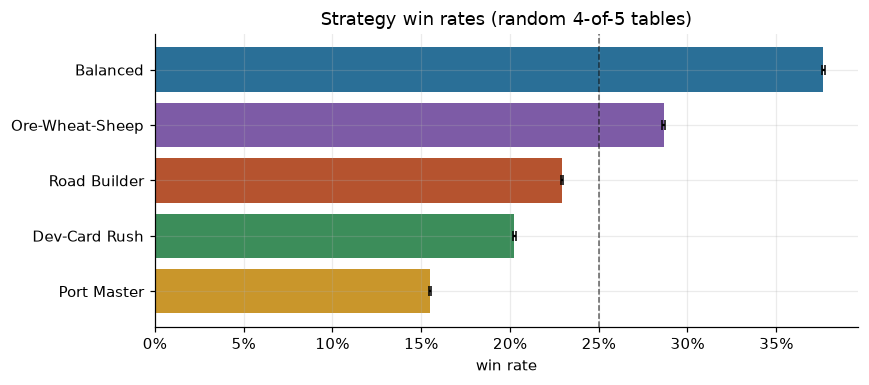

bot,games,win_rate,ci_low,ci_high,avg_vp,settlements,cities,dev_bought,trades,lr_in_wins,la_in_wins,turns_in_wins
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""balanced""",1599932,0.376428,0.375677,0.377179,7.95069,3.163274,1.898075,1.730917,6.559163,0.531157,0.057631,77.353345
"""ows""",1599620,0.28659,0.28589,0.287291,7.50443,0.562759,2.486472,5.938284,6.381954,0.036618,0.679874,77.695553
"""road_builder""",1600388,0.229294,0.228643,0.229946,7.377257,3.955308,0.912561,0.777652,6.399954,0.961939,0.012903,79.498026
"""dev_rush""",1599420,0.202587,0.201965,0.203211,6.988628,0.771922,1.688041,7.812136,6.487654,0.006873,0.944383,77.540263
"""port_master""",1600640,0.155141,0.154581,0.155703,6.569191,3.034597,1.471939,0.943674,9.127432,0.560302,0.030959,80.801663


In [2]:
s = summarize(df)
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(s.height)[::-1]
ax.barh(y, s['win_rate'], color=[COLORS[b] for b in s['bot']],
        xerr=[s['win_rate'] - s['ci_low'], s['ci_high'] - s['win_rate']], capsize=3)
ax.set_yticks(y, [LABELS[b] for b in s['bot']])
ax.axvline(0.25, color='k', lw=1, ls='--', alpha=0.6)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set_xlabel('win rate'); ax.set_title('Strategy win rates (random 4-of-5 tables)')
plt.tight_layout(); plt.show()
s.select(['bot', 'games', 'win_rate', 'ci_low', 'ci_high', 'avg_vp', 'settlements', 'cities', 'dev_bought', 'trades', 'lr_in_wins', 'la_in_wins', 'turns_in_wins'])

## How each strategy wins
The share of a strategy's wins in which it held Longest Road or Largest Army, and where its points came from.

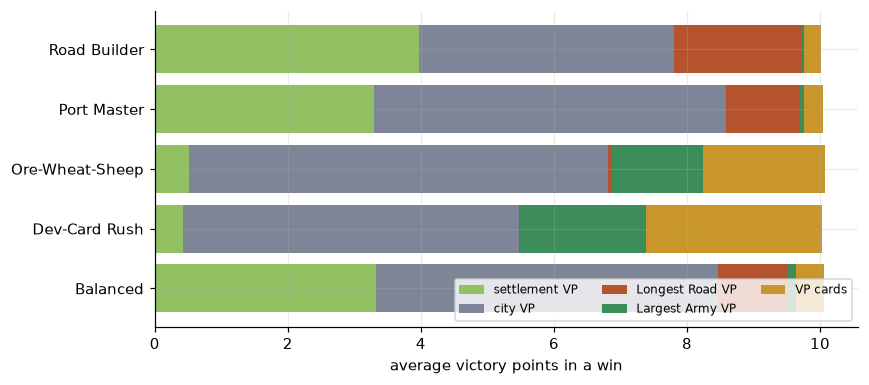

In [3]:
wins = df.filter(pl.col('won') == 1)
routes = wins.group_by('bot').agg(
    (pl.col('settlements')).mean().alias('settlement VP'),
    (2 * pl.col('cities')).mean().alias('city VP'),
    (2 * pl.col('longest_road')).mean().alias('Longest Road VP'),
    (2 * pl.col('largest_army')).mean().alias('Largest Army VP'),
    pl.col('vp_cards').mean().alias('VP cards'),
).sort('bot')
parts = ['settlement VP', 'city VP', 'Longest Road VP', 'Largest Army VP', 'VP cards']
fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(routes.height)
for p, c in zip(parts, ['#93c062', '#7d8597', '#b5532f', '#3c8d5a', '#c9962b']):
    ax.barh([LABELS[b] for b in routes['bot']], routes[p], left=left, label=p, color=c)
    left += routes[p].to_numpy()
ax.set_xlabel('average victory points in a win'); ax.legend(ncol=3, fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

## Seat advantage
Seat 1 places the first settlement and rolls first; seat 4 gets two placements in a row.

In [4]:
seat_advantage(df)

seat,win_rate,games
i64,f64,u32
0,0.274963,2000000
1,0.2604515,2000000
2,0.2426395,2000000
3,0.221946,2000000


## What each strategy produces

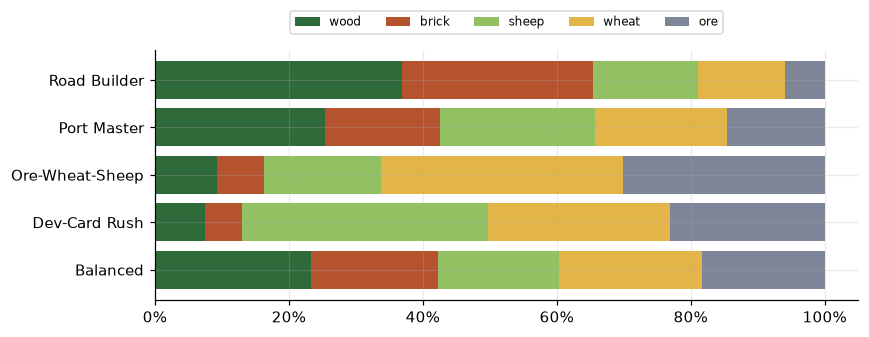

In [5]:
mix = resource_mix(df).sort('bot')
res = ['wood', 'brick', 'sheep', 'wheat', 'ore']
rc = ['#2f6b3a', '#b5532f', '#93c062', '#e3b448', '#7d8597']
fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(mix.height)
for r, c in zip(res, rc):
    ax.barh([LABELS[b] for b in mix['bot']], mix[r], left=left, color=c, label=r)
    left += mix[r].to_numpy()
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); ax.legend(ncol=5, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, 1.18))
plt.tight_layout(); plt.show()

## Skill ratings
OpenSkill (Plackett-Luce) ratings from finished games, ranking players by VP with the winner first.

In [6]:
openskill_ratings(df, max_games=20_000)

bot,mu,sigma,ordinal
str,f64,f64,f64
"""balanced""",26.587855,1.621314,21.723913
"""ows""",26.420984,1.627014,21.539944
"""road_builder""",25.357215,1.62181,20.491786
"""dev_rush""",22.981299,1.620369,18.120193
"""port_master""",19.589948,1.633656,14.688981


## Head-to-head: who finishes ahead of whom?
For every pair of strategies at the same table, how often the row strategy finishes with more VP than the column strategy (wins count as finishing first).

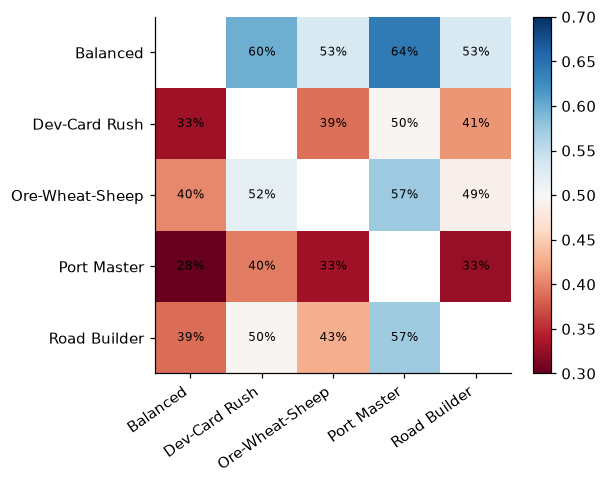

In [7]:
score = df.with_columns((pl.col('vp') + 100 * pl.col('won')).alias('score')).select(['game_id', 'bot', 'score'])
pairs = score.join(score, on='game_id', suffix='_o').filter(pl.col('bot') != pl.col('bot_o'))
h2h = pairs.group_by(['bot', 'bot_o']).agg(((pl.col('score') > pl.col('score_o')).mean()).alias('ahead'))
bots = sorted(df['bot'].unique().to_list())
M = np.full((len(bots), len(bots)), np.nan)
for r in h2h.iter_rows(named=True):
    M[bots.index(r['bot']), bots.index(r['bot_o'])] = r['ahead']
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(M, cmap='RdBu', vmin=0.3, vmax=0.7)
ax.set_xticks(range(len(bots)), [LABELS[b] for b in bots], rotation=35, ha='right')
ax.set_yticks(range(len(bots)), [LABELS[b] for b in bots])
for i in range(len(bots)):
    for j in range(len(bots)):
        if i != j: ax.text(j, i, f'{M[i, j]:.0%}', ha='center', va='center', fontsize=8)
ax.grid(False); plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()